In [ ]:
#open colab file picker to choose files needed
from google.colab import files

uploaded = files.upload()

Saving dataset.xlsx to dataset (5).xlsx


In [ ]:
#load the data
import pandas as pd

df = pd.read_excel("/content/dataset.xlsx")

print("Dataset size:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

Dataset size: (886, 61)
Column names: ['Unnamed: 0', 'Heavy / Extreme menstrual bleeding', 'Menstrual pain (Dysmenorrhea)', 'Painful / Burning pain during sex (Dyspareunia)', 'Pelvic pain', 'Irregular / Missed periods', 'Cramping', 'Abdominal pain / pressure', 'Back pain', 'Painful bowel movements', 'Nausea', 'Menstrual clots', 'Infertility', 'Painful cramps during period', 'Pain / Chronic pain', 'Diarrhea', 'Long menstruation', 'Constipation / Chronic constipation', 'Vomiting / constant vomiting', 'Fatigue / Chronic fatigue', 'Painful ovulation', 'Stomach cramping', 'Migraines', 'Extreme / Severe pain', 'Leg pain', 'Irritable Bowel Syndrome (IBS)', 'Syncope (fainting, passing out)', 'Mood swings', 'Depression', 'Bleeding', 'Lower back pain', 'Fertility Issues', 'Ovarian cysts', 'Painful urination', 'Headaches', 'Constant bleeding', 'Pain after Intercourse', 'Digestive / GI problems', 'IBS-like symptoms', 'Excessive bleeding', 'Anaemia / Iron deficiency', 'Hip pain', 'Vaginal Pain/Pres

,Unnamed: 0,Heavy / Extreme menstrual bleeding,Menstrual pain (Dysmenorrhea),Painful / Burning pain during sex (Dyspareunia),Pelvic pain,Irregular / Missed periods,Cramping,Abdominal pain / pressure,Back pain,Painful bowel movements,...,Hormonal problems,Bloating,Feeling sick,Decreased energy / Exhaustion,Abdominal Cramps during Intercourse,Insomnia / Sleeplessness,Acne / pimples,Loss of appetite,row,Has endo(1) or not(0)
0,Heavy / Extreme menstrual bleeding;Fatigue / C...,1,1,1,1,1,1,1,1,1,...,0,1,1,1,1,0,0,0,0,1
1,Heavy / Extreme menstrual bleeding;Nausea;Pain...,1,1,1,1,1,1,1,1,1,...,0,0,1,1,1,0,0,1,1,1
2,Fatigue / Chronic fatigue;Nausea;Bloating;Back...,0,1,0,1,1,1,0,1,0,...,0,1,1,1,0,1,0,0,2,1
3,Heavy / Extreme menstrual bleeding;Fatigue / C...,1,0,0,0,0,1,1,1,0,...,0,1,0,1,0,0,0,0,3,1
4,Fatigue / Chronic fatigue;Painful / Burning pa...,0,1,1,0,0,1,0,1,1,...,0,0,0,0,0,0,0,0,4,1


In [ ]:
#label counts and missing values
print("Endometriosis label counts:")
print(df["Has endo(1) or not(0)"].value_counts()) #prints on the target

print("\nMissing values:", df.isnull().sum().sum())




Endometriosis label counts:
Has endo(1) or not(0)
1    474
0    412
Name: count, dtype: int64

Missing values: 0


In [ ]:

target = "Has endo(1) or not(0)"

# Identify the symptom columns apart from extra
extra = ["Unnamed: 0", "row", target]
symptoms = [c for c in df.columns if c not in extra]

print("Number of symptom columns:", len(symptoms))

print("\nValues used in the symptom columns:")
print(sorted(pd.unique(df[symptoms].values.ravel())))

print("\nValues used in the target column:")
print(sorted(df[target].unique()))

print("\nIs the row column unique?")
print(df["row"].is_unique)  #proves row is just an ID without any meaning

Number of symptom columns: 58

Values used in the symptom columns:
[np.int64(0), np.int64(1)]

Values used in the target column:
[np.int64(0), np.int64(1)]

Is the row column unique?
True


In [ ]:
# Name of the target/outcome column
#building the modelling set
target = "Has endo(1) or not(0)"

# Create a working copy without the extra columns
df_work = df.drop(columns=["Unnamed: 0", "row"]).copy()  # copy keeps the original df untouched

# Separate symptoms from the outcome
X = df_work.drop(columns=[target])  # features minus target
y = df_work[target]                 # target

# Display the results
print("Dataset size:", df_work.shape)
print("Number of symptom features:", X.shape[1])
print("Number of outcome labels:", y.shape[0])

Dataset size: (886, 59)
Number of symptom features: 58
Number of outcome labels: 886


In [ ]:
# Exploratory Data Analysis
# Calculate how often each symptom appears(most and lest common symptoms)
symptom_percent = X.mean() * 100

print("10 most common symptoms (%)")
display(
    symptom_percent.sort_values(ascending=False)
    .head(10).round(1)
)

print("10 least common symptoms (%)")
display(
    symptom_percent.sort_values()
    .head(10).round(1)
)

10 most common symptoms (%)


,0
Cramping,54.7
Back pain,54.3
Bleeding,50.9
Pelvic pain,49.1
Menstrual pain (Dysmenorrhea),43.2
Heavy / Extreme menstrual bleeding,43.2
Fatigue / Chronic fatigue,42.7
Painful / Burning pain during sex (Dyspareunia),41.3
Abdominal pain / pressure,40.9
Lower back pain,40.0


10 least common symptoms (%)


,0
"Syncope (fainting, passing out)",8.0
Abnormal uterine bleeding,8.7
Constant bleeding,10.6
Malaise / Sickness,12.1
Fertility Issues,14.7
Excessive bleeding,16.8
Fever,17.3
Vomiting / constant vomiting,18.5
Irritable Bowel Syndrome (IBS),19.0
Painful urination,19.9


### EDA Findings: Symptom Frequency

**Observation 1: Common symptoms.** Cramping was the most frequently recorded symptom which appears in 54.7% of the 886 records followed by back pain followed at 54.3% while bleeding appeared in 50.9% of records.

**Observation 2: Less common symptoms.** Syncope (fainting or passing out) was the least frequently recorded symptom which appears in 8.0% of records. Abnormal uterine bleeding followed at 8.7%.

**Interpretation:** The frequency of symptoms varies considerably across the dataset then again as much as these results describe symptom occurrence in the available records they do not establish which symptoms are most useful for distinguishing who has or does not have endometriosis

In [ ]:
#Find out which symptoms differentiate the two groups of people who have and who do not have endometriosis
# Calculate symptom percentages separately for each group
rates = df_work.groupby("Has endo(1) or not(0)")[X.columns].mean().T * 100

# Give the columns clearer names
rates.columns = ["No endometriosis (0)", "Endometriosis (1)"]

# Calculate the difference between the two groups
rates["Difference"] = (
    rates["Endometriosis (1)"] - rates["No endometriosis (0)"]
)

# Show symptoms with the largest positive differences
display(rates.sort_values("Difference", ascending=False).head(10).round(1))

,No endometriosis (0),Endometriosis (1),Difference
Menstrual pain (Dysmenorrhea),5.3,76.2,70.8
Cramping,22.6,82.7,60.1
Painful cramps during period,7.0,66.9,59.8
Fatigue / Chronic fatigue,10.9,70.3,59.3
Heavy / Extreme menstrual bleeding,11.7,70.7,59.0
Bleeding,20.4,77.4,57.0
Pelvic pain,18.7,75.5,56.8
Abdominal pain / pressure,11.2,66.7,55.5
Painful / Burning pain during sex (Dyspareunia),12.1,66.7,54.5
Back pain,28.2,77.0,48.8


**Observation 3: Differences in symptom frequency between the two groups.** Menstrual pain (dysmenorrhea) showed the largest difference among the ten symptoms listed appearing in 76.2% of records labelled as having endometriosis and 5.3% of records labelled as not having endometriosis. This represents a difference of approximately 70.8 percentage points. Cramping also showed a difference, occurring in 82.7% of records labelled as having endometriosis compared with 22.6% of records labelled as not having endometriosis.

**Interpretation:** Several symptoms occur more frequently in the endometriosis-labelled group in this dataset. These patterns may help identify useful predictors for classification.

In [ ]:
#Show the 10 symptoms with the smallest group differences to reveal the most similar similarities/ frequencies between the two groups
#and symptoms that may be less usefull for distinguishing
display(rates.reindex(
    rates["Difference"].abs().sort_values().index
).head(10).round(1))

,No endometriosis (0),Endometriosis (1),Difference
Malaise / Sickness,7.5,16.0,8.5
Abnormal uterine bleeding,4.1,12.7,8.5
Fever,23.1,12.2,-10.8
"Syncope (fainting, passing out)",1.0,14.1,13.2
Constant bleeding,3.4,16.9,13.5
Loss of appetite,19.9,34.0,14.1
Vomiting / constant vomiting,10.2,25.7,15.5
Migraines,29.6,45.6,16.0
Fertility Issues,5.1,23.0,17.9
Bowel pain,13.6,35.2,21.6


**Observation 4: Differences in less-discriminating symptom features.** Among the symptoms displayed in the comparison of smaller absolute group differences, several were more frequent in records labelled as having endometriosis. For example, bowel pain occurred in 35.2% of records labelled 1 and 13.6% of records labelled 0, a difference of 21.6 percentage points. However, fever showed the opposite pattern, occurring in 23.1% of records labelled 0 and 12.2% labelled 1.

**Interpretation:** Symptom frequencies do not follow one uniform pattern across the two groups. These comparisons can help identify features for modelling but they do not establish any importance in predictive usefulness.

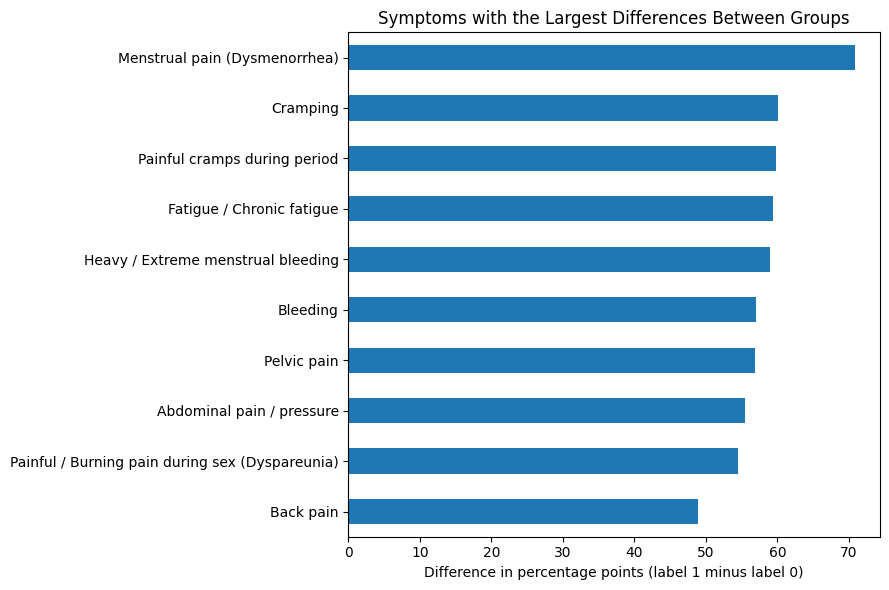

In [ ]:
#A chart showing visual differences
import matplotlib.pyplot as plt

# Find the 10 symptoms with the largest absolute differences
top10 = rates["Difference"].abs().nlargest(10).index    # select 10 largest gaps

# Plot their actual differences
rates.loc[top10, "Difference"].sort_values().plot(
    kind="barh", figsize=(9, 6)    #barh draws horizontally
)

plt.axvline(0)
plt.xlabel("Difference in percentage points (label 1 minus label 0)")
plt.title("Symptoms with the Largest Differences Between Groups")
plt.tight_layout()
plt.show()

In [ ]:
# Duplicate check in symptom patterns
print("Repeated symptom patterns:", X.duplicated().sum())
print("Rows in repeated patterns:", X.duplicated(keep=False).sum())

data_check = X.copy()
data_check["target"] = y

label_counts = data_check.groupby(
    list(X.columns)
)["target"].nunique()

print(
    "Patterns associated with both labels:",
    (label_counts > 1).sum()
)

Repeated symptom patterns: 34
Rows in repeated patterns: 65
Patterns associated with both labels: 1


In [ ]:
# Find symptom patterns associated with both labels
pattern_labels = df_work.groupby(list(X.columns))[target].nunique()

conflicts = pattern_labels[pattern_labels > 1].index

# Find all records with those patterns of more than one label
mask = pd.MultiIndex.from_frame(X).isin(conflicts)

print("Records with this pattern:", mask.sum())

print("\nLabels assigned to these records:")
print(y[mask].value_counts().sort_index())

print("\nSymptoms present in this pattern:")
row = X.loc[mask].iloc[0]
print(row[row == 1].index.tolist())

Records with this pattern: 2

Labels assigned to these records:
Has endo(1) or not(0)
0    1
1    1
Name: count, dtype: int64

Symptoms present in this pattern:
['Painful / Burning pain during sex (Dyspareunia)', 'Back pain', 'Painful cramps during period']


In [ ]:
#displays the two original record
display(
    df.loc[mask, [
        "row",
        "Unnamed: 0",
        "Has endo(1) or not(0)"
    ]]
)

,row,Unnamed: 0,Has endo(1) or not(0)
54,54,Painful / Burning pain during sex (Dyspareunia...,1
496,496,Painful / Burning pain during sex (Dyspareunia...,0


In [ ]:
# Show the full symptom summaries for the two records
conflict_rows = df.loc[mask]

for _, record in conflict_rows.iterrows():
    print("Row:", record["row"])
    print("Label:", record[target])
    print("Symptoms:", record["Unnamed: 0"])
    print("-" * 40)

# Check whether the text summaries are identical
summaries = conflict_rows["Unnamed: 0"].tolist()

print("Are the full summaries identical?", summaries[0] == summaries[1])

Row: 54
Label: 1
Symptoms: Painful / Burning pain during sex (Dyspareunia);Back pain;Painful cramps during period
----------------------------------------
Row: 496
Label: 0
Symptoms: Painful / Burning pain during sex (Dyspareunia);Back pain;Painful cramps during period
----------------------------------------
Are the full summaries identical? True


**Conflicting labels.** Two records (rows 54 and 496) contained identical values across all 58 symptom features and identical symptom summaries, but had different target labels. This finding was documented without deleting either record because the correct label cannot be established from the symptom features alone.

In [ ]:
# check for duplicate for identical symptom columns

duplicates = X.columns[X.T.duplicated()].tolist()

print("Number of duplicate symptom columns:", len(duplicates))
print("Duplicate columns:", duplicates)

Number of duplicate symptom columns: 0
Duplicate columns: []


In [ ]:
# Check for symptoms that have the same 1 or 0 in all records because basically they cannot help you differenciate records
constant = [col for col in X.columns if X[col].nunique() == 1]

print("Constant symptom columns:", constant)

# Check whether any symptom exactly matches the target
matches = [col for col in X.columns if (X[col] == y).all()]

# Check whether any symptom is the exact opposite of the target
opposites = [col for col in X.columns if (X[col] == 1 - y).all()]

print("Columns matching the target exactly:", matches)
print("Columns opposite to the target exactly:", opposites)

Constant symptom columns: []
Columns matching the target exactly: []
Columns opposite to the target exactly: []


### Data Cleaning and Exploratory Data Analysis

### 1. Data Cleaning and Preparation

The dataset was loaded from the Excel file `dataset.xlsx` into a Pandas DataFrame. Initial inspection identified 886 records, 58 symptom features, and one target column, `Has endo(1) or not(0)`.

The following checks and preparation steps were performed:

- **Missing values:** No missing values were detected.
- **Duplication records:** The dataset has 34 repeated symptom patterns, one pair of rows has identical symptoms with different labels.
- **Duplicate features:** No two symptom columns contained identical values across all records.
- **Constant features:** No symptom column had the same value for every record.
- **Exact target matches:** No symptom column matched the target exactly or contained its exact inverse.

A working copy named `df_work` was created, and the data was separated into `X`, containing 58 symptom features, and `y`, containing the target labels. The original DataFrame was retained unchanged.

### 2. Exploratory Data Analysis

EDA was performed to examine symptom frequencies and compare symptom patterns between the two groups. A bar chart was also created to visualize the symptoms with the largest differences in frequency between the groups.
The findings are documented above.


### 3. Data Limitations

The method used to assign the original target labels has not yet been verified due to the dataset being a combination of different datasets.Therefore, the findings describe patterns within the available dataset and are not to be used/interpreted as evidence of diagnostic accuracy or clinical decisions.


In [ ]:

# Import the tools needed for data splitting and machine learning.
from sklearn.model_selection import StratifiedGroupKFold

# Convert each row of binary symptoms into a profile identifier.
# Identical symptom profiles will have the same identifier.
groups = X.astype(int).astype(str).agg("".join, axis=1)

# Check how many unique symptom profiles exist.
print("Total records:", len(X))
print("Unique symptom profiles:", groups.nunique())
print("Records in repeated profiles:", groups.duplicated(keep=False).sum())

# Verify that identical symptom profiles receive consistent group IDs.
assert len(groups) == len(X)
print("Grouping completed.")


Total records: 886
Unique symptom profiles: 852
Records in repeated profiles: 65
Grouping completed.


In [ ]:

# Create five folds while keeping identical symptom profiles together.
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Select the first fold as the final holdout test set.
train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Create separate training and testing features and labels.
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

# Confirm that no symptom profile occurs in both sets.
overlap = set(groups_train) & set(groups_test)
assert len(overlap) == 0, "Data leakage: profiles overlap!"

# Display the sizes and class distributions.
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting label distribution:")
print(y_test.value_counts().sort_index())

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

print("\nNo identical symptom profiles overlap between the sets.")


Training records: 709
Testing records: 177

Training label distribution:
Has endo(1) or not(0)
0    333
1    376
Name: count, dtype: int64

Testing label distribution:
Has endo(1) or not(0)
0    79
1    98
Name: count, dtype: int64

Training class proportions:
Has endo(1) or not(0)
0    0.47
1    0.53
Name: proportion, dtype: float64

Testing class proportions:
Has endo(1) or not(0)
0    0.446
1    0.554
Name: proportion, dtype: float64

No identical symptom profiles overlap between the sets.


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the baseline Logistic Regression model
logistic_model = LogisticRegression(
    C=1.0,
    penalty="l2",
    solver="lbfgs",
    max_iter=2000,
    random_state=42
)

# Train the model using the training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")
print("Number of training records:", len(X_train))
print("Number of symptom features:", X_train.shape[1])

Logistic Regression model trained successfully!
Number of training records: 709
Number of symptom features: 58


In [ ]:
# Predict labels for the testing records
y_pred = logistic_model.predict(X_test)

# Obtain predicted probabilities for label 1
y_probability = logistic_model.predict_proba(X_test)[:, 1]

# Display a sample of the predictions
results = pd.DataFrame({
    "Actual label": y_test.to_numpy(),
    "Predicted label": y_pred,
    "Predicted probability for label 1": y_probability
})

display(results.head(10))

,Actual label,Predicted label,Predicted probability for label 1
0,1,1,0.999581
1,1,1,0.874963
2,1,1,0.957378
3,1,0,0.073382
4,1,1,0.739828
5,1,1,0.768825
6,1,1,0.909074
7,1,1,0.914720
8,1,0,0.448494
9,1,1,0.955189


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    classification_report
)

print("MODEL EVALUATION")

print(f"Accuracy:          {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision:         {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall:            {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score:          {f1_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"MCC:               {matthews_corrcoef(y_test, y_pred):.3f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, y_probability):.3f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Label 0", "Label 1"],
    zero_division=0
))

MODEL EVALUATION
Accuracy:          0.938
Precision:         0.978
Recall:            0.908
F1-score:          0.942
Balanced accuracy: 0.941
MCC:               0.878
ROC-AUC:           0.989

Detailed classification report:
              precision    recall  f1-score   support

     Label 0       0.90      0.97      0.93        79
     Label 1       0.98      0.91      0.94        98

    accuracy                           0.94       177
   macro avg       0.94      0.94      0.94       177
weighted avg       0.94      0.94      0.94       177



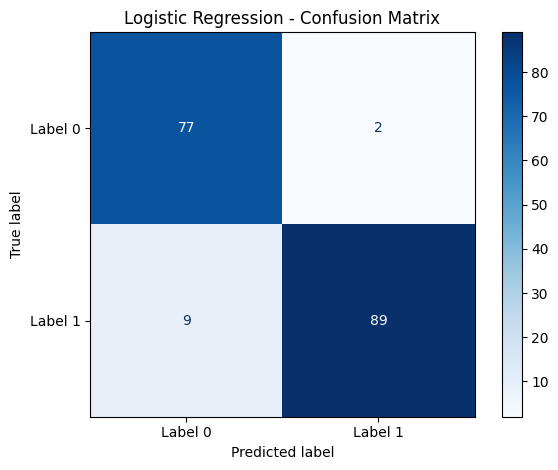

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Label 0", "Label 1"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

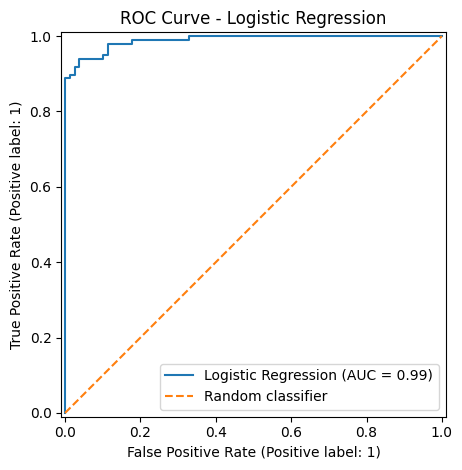

In [ ]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# Plot the ROC curve for Logistic Regression
RocCurveDisplay.from_predictions(
    y_test,
    y_probability,
    name="Logistic Regression"
)

# Add a reference line for random classification
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create five grouped folds
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_model = clone(logistic_model)
cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(
        X_train,
        y_train,
        groups=groups.loc[X_train.index]
    ),
    start=1
):
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    if y_fold_train.nunique() < 2 or y_fold_val.nunique() < 2:
        print(f"Fold {fold} skipped: only one class present.")
        continue

    model = clone(baseline_model)
    model.fit(X_fold_train, y_fold_train)

    fold_pred = model.predict(X_fold_val)
    fold_prob = model.predict_proba(X_fold_val)[:, 1]

    cv_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_fold_val, fold_pred),
        "Precision": precision_score(
            y_fold_val, fold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_fold_val, fold_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_fold_val, fold_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_fold_val, fold_prob)
    })

cv_df = pd.DataFrame(cv_results)

print("CROSS-VALIDATION RESULTS")
display(cv_df.round(3))

if not cv_df.empty:
    print("\nMean and standard deviation across folds:")
    display(
        cv_df.drop(columns="Fold")
        .agg(["mean", "std"])
        .round(3)
    )
else:
    print("No valid folds were evaluated. Check the class distribution.")


CROSS-VALIDATION RESULTS


,Fold,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,1,0.901,0.888,0.934,0.910,0.963
1,2,0.908,0.908,0.920,0.914,0.970
2,3,0.928,0.985,0.880,0.930,0.987
3,4,0.972,0.986,0.959,0.973,0.998
4,5,0.916,0.944,0.895,0.919,0.970



Mean and standard deviation across folds:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
mean,0.925,0.942,0.918,0.929,0.978
std,0.028,0.045,0.032,0.025,0.015


In [ ]:

from sklearn.utils.validation import check_is_fitted

try:
    check_is_fitted(logistic_model)

    print("SUCCESS: Logistic Regression is trained!")
    print("The model is ready to make predictions.")

except Exception as e:
    print("The model is not fitted yet.")
    print("Details:", e)


SUCCESS: Logistic Regression is trained!
The model is ready to make predictions.


In [ ]:

# Select one record from the held-out test set
sample = X_test.iloc[[0]]

# Ask the trained model for its prediction
prediction = logistic_model.predict(sample)

# Get the estimated probability for each class
probabilities = logistic_model.predict_proba(sample)[0]

print("MODEL PREDICTION TEST")
print("---------------------")
print("Predicted label:", prediction[0])
print(f"Probability of label 0: {probabilities[0]:.2%}")
print(f"Probability of label 1: {probabilities[1]:.2%}")

# Compare with the actual dataset label
print("Actual label:", y_test.iloc[0])


MODEL PREDICTION TEST
---------------------
Predicted label: 1
Probability of label 0: 0.04%
Probability of label 1: 99.96%
Actual label: 1


In [ ]:
# Check for overlap between training and testing profiles

train_profiles = set(groups.loc[X_train.index])
test_profiles = set(groups.loc[X_test.index])

overlap = train_profiles.intersection(test_profiles)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Overlapping symptom profiles:", len(overlap))

if len(overlap) == 0:
    print("PASS: No symptom profiles overlap.")
else:
    print("WARNING: Some symptom profiles overlap.")


Training records: 709
Testing records: 177
Overlapping symptom profiles: 0
PASS: No symptom profiles overlap.


In [ ]:
# Check whether the dataset and required variables exist

print("Dataset df exists:", "df" in globals())
print("Features X exist:", "X" in globals())
print("Target y exists:", "y" in globals())
print("Training data exists:", "X_train" in globals())
print("Logistic Regression exists:", "logistic_model" in globals())

Dataset df exists: True
Features X exist: True
Target y exists: True
Training data exists: True
Logistic Regression exists: True


In [ ]:

from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Define the models
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": DecisionTreeClassifier(
        random_state=59,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=59,
        class_weight="balanced"
    )
}

# Set up 5-fold grouped cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=59
)

cv_results = []

# Evaluate each model
for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },
        n_jobs=-1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean()*100,
        "Mean Balanced Accuracy":
            scores["test_balanced_accuracy"].mean()*100,
        "Mean Precision": scores["test_precision"].mean()*100,
        "Mean Recall": scores["test_recall"].mean()*100,
        "Mean F1": scores["test_f1"].mean()*100
    })

cv_df = pd.DataFrame(cv_results)

print(cv_df.round(3).to_string(index=False))


              Model  Mean Accuracy  Mean Balanced Accuracy  Mean Precision  Mean Recall  Mean F1
Logistic Regression         92.343                  92.496          93.664       91.796   92.666
      Decision Tree         86.031                  86.088          85.949       88.452   87.021
      Random Forest         92.084                  92.258          93.669       91.274   92.401


In [ ]:

from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Define the three models
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": DecisionTreeClassifier(
        random_state=59,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=59,
        class_weight="balanced"
    )
}

# Set up five-fold grouped cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=59
)

results = []

for name, model in models.items():

    # Measure training and validation accuracy across five folds
    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring="accuracy",
        return_train_score=True,
        n_jobs=-1,
        error_score="raise"
    )

    # Train the model using the full training dataset
    model.fit(X_train, y_train)

    # Record the three accuracy measurements
    results.append({
        "Model": name,
        "Training Accuracy":
            scores["train_score"].mean() * 100,
        "Validation Accuracy":
            scores["test_score"].mean() * 100,
        "Test Accuracy":
            model.score(X_test, y_test) * 100
    })

# Display the comparison table
results_df = pd.DataFrame(results)

print("Model Accuracy Comparison")
print(results_df.round(3).to_string(index=False))


Model Accuracy Comparison
              Model  Training Accuracy  Validation Accuracy  Test Accuracy
Logistic Regression             95.662               92.343         93.785
      Decision Tree             99.859               86.031         85.311
      Random Forest             99.859               92.084         92.090


**Step 4: Further Validation of the Base Model**

To validate the baseline model, Decision Tree and Random Forest classifiers were developed and evaluated using the same training and test datasets. Their performance was compared using accuracy, balanced accuracy, precision, recall and F1 score.

Accuracy measured how many predictions were correct overall. Balanced accuracy measured how well the model performed across both classes. Precision measured how often was the model correct when it predicted positive. Recall measured how many actual positives the model correctly identified out of all the positives. The F1 Score measured how well the model balanced precision and recall.

Five-fold stratified group cross-validation was performed on the training data. This method divides the training data into five folds, using four folds for training and one for validation in each round. Stratification helps maintain the distribution of the target classes while grouping keeps identical symptom profiles together to reduce potential data leakage.

The results showed that logistic regression had the highest mean accuracy of 92.343%, balanced accuracy of 92.496%, precision of 93.664%, recall of 91.796% and F1 score of 92.666%. Random Forest had a mean accuracy of 92.084%, balanced accuracy of 92.258%, precision of 93.669%, recall of 91.274% and F1 score of 92.401%. And Decision Tree had a mean accuracy of 86.031%, balanced accuracy of 86.088%, precision of 85.949%, recall of 88.452% and F1 score of 87.021%.

The results showed that Logistic Regression achieved a training accuracy of 95.662%, a validation accuracy of 92.343% and a test accuracy of 93.785% making it the best performer on the held-out test set. The Decision Tree almost achieves a perfect training accuracy(99.859%) but has a lower validation(86.031%) and test accuracy(85.311%) which suggests overfitting that occurs due to the model learning the training data too closely. Random Forest also has a high training accuracy(99.859%) but has its validation and test accuracy close to Logistic regression's.

Overall, Logistic Regression performed best across all five evaluation metrics followed by Random Forest then Decision Tree. This suggests that Logistic Regression model was more effective at predicting the dataset labels. However, the results demonstrate predictive performance on the available dataset rather than proven clinical diagnostic accuracy.


